# 🌾 Агро-хакатон: кліматичні дані для рекомендацій щодо сівозміни

**Мета проєкту:** допомагати фермерам приймати рішення щодо сівозміни на основі стану ґрунтів та природних умов.
Економічні показники (прибуток, ціни) свідомо **не враховуємо**.

**Що робить цей ноутбук:**
1. Імпортує бібліотеки
2. Завантажує місячні агро-кліматичні дані з NASA POWER API
3. Робить просте очищення та EDA
4. Готує базову кластеризацію K-Means (відправна точка)

## Крок 1. Імпорт бібліотек

Беремо лише найнеобхідніше: роботу з даними (`pandas`, `numpy`), запити до API (`requests`, `json`),
візуалізацію (`seaborn`, `matplotlib`) і базові інструменти `sklearn` для кластеризації.

In [2]:
import json
import requests
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, silhouette_score

sns.set_theme(style="whitegrid")

## Крок 2. Імпорт даних через NASA POWER API

Робимо GET-запит до місячного ендпоінта NASA POWER для однієї точки.

- **Координати:** latitude=40, longitude=-96 (точка на північному кордоні Канзасу; NASA POWER повертає дані для найближчої комірки сітки)
- **Період:** 2025–2026 (місячні дані)
- **Параметри** (замість порожнього `parameters=%3B` з попередньої спроби):
  - `T2M`, `T2M_MAX`, `T2M_MIN` – температура повітря на 2 м (°C): середня, максимальна, мінімальна
  - `PRECTOTCORR` – опади (мм/день)
  - `GWETROOT` – вологість кореневої зони ґрунту (0–1)
  - `GWETTOP` – вологість поверхневого шару ґрунту (0–1)
  - `RH2M` – відносна вологість повітря (%)
  - `ALLSKY_SFC_SW_DWN` – сонячна радіація (кВт·год/м²/день)

> Параметри передаємо через словник `params`: `requests` сам коректно закодує URL.

In [3]:
url = "https://power.larc.nasa.gov/api/temporal/monthly/point"

params = {
    "parameters": "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,GWETROOT,GWETTOP,RH2M,ALLSKY_SFC_SW_DWN",
    "community": "AG",
    "latitude": 40,
    "longitude": -96,
    "start": 2010,
    "end": 2026,
    "format": "JSON",
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()   # якщо буде помилка запиту – побачимо її одразу

data = response.json()
print("Запит виконано:", response.url)
print("Ключі відповіді:", list(data.keys()))

Запит виконано: https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=T2M%2CT2M_MAX%2CT2M_MIN%2CPRECTOTCORR%2CGWETROOT%2CGWETTOP%2CRH2M%2CALLSKY_SFC_SW_DWN&community=AG&latitude=40&longitude=-96&start=2010&end=2026&format=JSON
Ключі відповіді: ['type', 'geometry', 'properties', 'header', 'messages', 'parameters', 'times']


### Перетворення JSON у DataFrame

Дані лежать у `data["properties"]["parameter"]` у вигляді `{параметр: {"YYYYMM": значення}}`.
Pandas одразу перетворює таку структуру в таблицю, де рядки – місяці, а колонки – параметри.

Особливості NASA POWER:
- ключі виду `2025MM` – це місяці, а `202513` – **середнє за рік**, його прибираємо;
- пропущені значення позначені як `-999`, замінюємо їх на `NaN`.

In [4]:
parameter_dict = data["properties"]["parameter"]

df = pd.DataFrame(parameter_dict)

# прибираємо річні підсумки (ключі, що закінчуються на "13")
df = df[~df.index.str.endswith("13")]

# -999 – це "немає даних"
df = df.replace(-999, np.nan)

# індекс -> дата (перше число місяця)
df.index = pd.to_datetime(df.index, format="%Y%m")
df.index.name = "date"

df.head()

,ALLSKY_SFC_SW_DWN,GWETROOT,GWETTOP,PRECTOTCORR,RH2M,T2M,T2M_MAX,T2M_MIN
date,,,,,,,,
2010-01-01,7.43,0.66,0.69,0.50,88.93,-6.83,11.64,-29.09
2010-02-01,10.33,0.67,0.70,0.90,81.76,-3.56,7.49,-15.95
2010-03-01,12.87,0.69,0.72,2.63,79.88,5.01,23.75,-6.14
2010-04-01,18.39,0.68,0.71,2.95,70.30,13.93,26.64,-0.61
2010-05-01,20.18,0.68,0.71,3.49,74.33,16.29,29.79,2.01


## Крок 3. Очищення та EDA

Використовуємо прості стандартні функції. Спочатку перевіряємо структуру та пропуски.
Місяці, для яких NASA ще не має даних (наприклад, кінець 2026 року), видаляємо.

In [5]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 203 entries, 2010-01-01 to 2026-11-01
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ALLSKY_SFC_SW_DWN  199 non-null    float64
 1   GWETROOT           201 non-null    float64
 2   GWETTOP            201 non-null    float64
 3   PRECTOTCORR        201 non-null    float64
 4   RH2M               201 non-null    float64
 5   T2M                201 non-null    float64
 6   T2M_MAX            201 non-null    float64
 7   T2M_MIN            201 non-null    float64
dtypes: float64(8)
memory usage: 14.3 KB


In [6]:
print("Пропуски по колонках:")
print(df.isna().sum())

# видаляємо місяці без даних
df = df.dropna()
print("\nРядків після очищення:", len(df))

Пропуски по колонках:
ALLSKY_SFC_SW_DWN    4
GWETROOT             2
GWETTOP              2
PRECTOTCORR          2
RH2M                 2
T2M                  2
T2M_MAX              2
T2M_MIN              2
dtype: int64

Рядків після очищення: 199


In [7]:
df.tail()

,ALLSKY_SFC_SW_DWN,GWETROOT,GWETTOP,PRECTOTCORR,RH2M,T2M,T2M_MAX,T2M_MIN
date,,,,,,,,
2026-03-01,15.56,0.56,0.57,0.88,63.88,9.30,31.96,-11.87
2026-04-01,17.89,0.58,0.61,4.59,67.40,14.12,29.08,0.45
2026-05-01,22.33,0.59,0.61,4.39,64.31,18.25,33.13,0.94
2026-06-01,21.68,0.61,0.64,4.48,75.17,23.08,33.48,11.25
2026-07-01,22.27,0.55,0.56,4.70,71.60,26.55,38.73,16.82


In [8]:
df.describe()

,ALLSKY_SFC_SW_DWN,GWETROOT,GWETTOP,PRECTOTCORR,RH2M,T2M,T2M_MAX,T2M_MIN
count,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,15.452965,0.580000,0.591809,2.297588,70.337487,11.994724,27.561508,-1.998744
std,5.975909,0.071145,0.085267,1.737652,8.030354,10.548970,8.926348,11.918178
min,4.780000,0.470000,0.350000,0.040000,44.300000,-6.830000,7.490000,-31.660000
25%,10.310000,0.535000,0.535000,0.835000,65.515000,2.520000,20.500000,-10.985000
50%,15.500000,0.560000,0.580000,2.020000,70.300000,12.760000,28.960000,-2.570000
75%,20.520000,0.605000,0.630000,3.375000,75.275000,22.410000,35.295000,9.125000
max,26.910000,0.840000,0.840000,8.920000,90.700000,30.320000,42.660000,18.980000


### Візуалізація 1: кореляції між показниками

Теплова карта показує, які кліматичні параметри пов'язані між собою
(наприклад, температура й сонячна радіація, опади й вологість ґрунту).

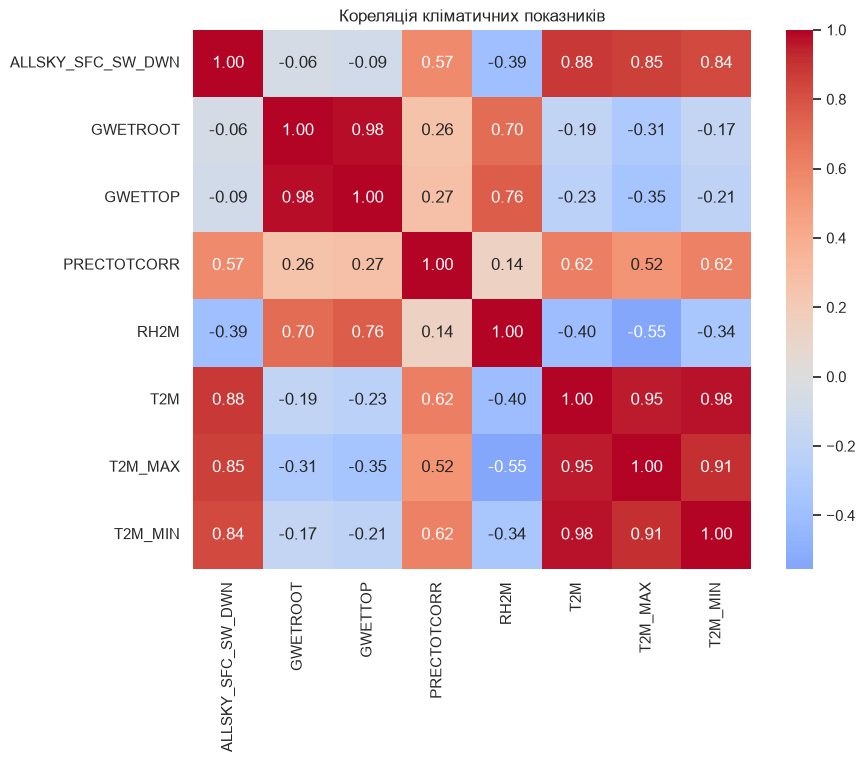

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Кореляція кліматичних показників")
plt.show()

### Візуалізація 2: температура, опади та вологість ґрунту в часі

Дивимось, як змінюються ключові показники по місяцях.

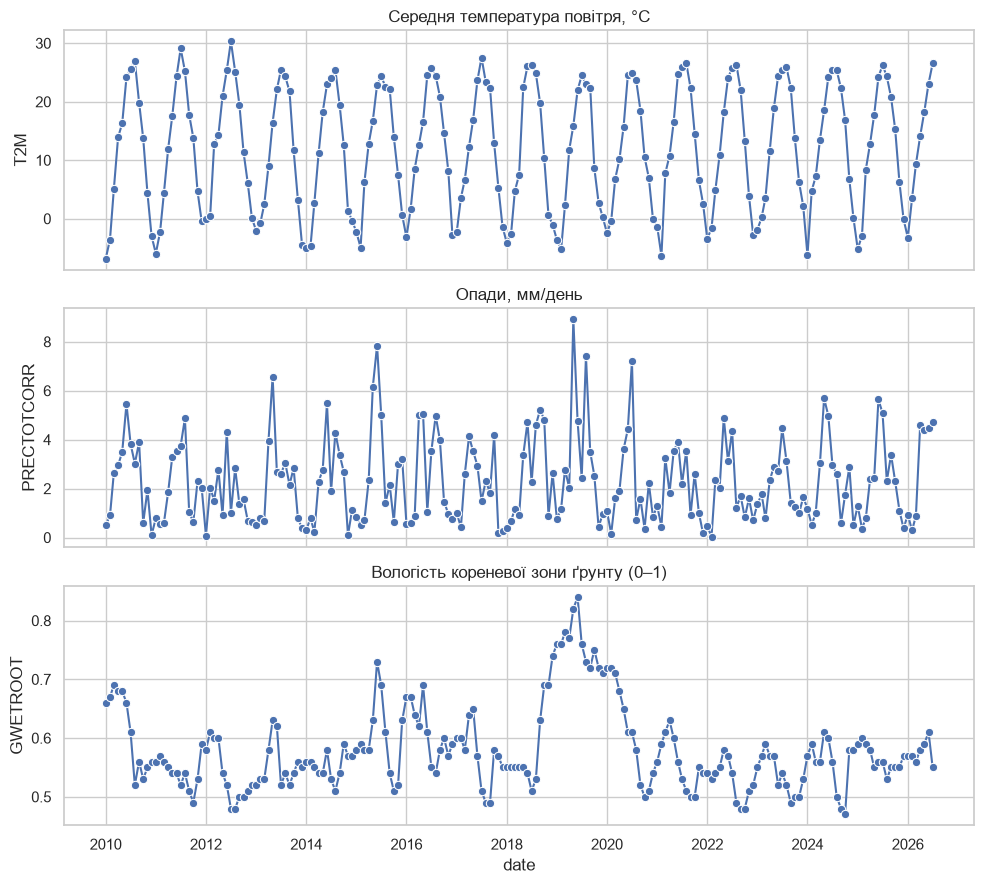

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

sns.lineplot(data=df, x=df.index, y="T2M", marker="o", ax=axes[0])
axes[0].set_title("Середня температура повітря, °C")

sns.lineplot(data=df, x=df.index, y="PRECTOTCORR", marker="o", ax=axes[1])
axes[1].set_title("Опади, мм/день")

sns.lineplot(data=df, x=df.index, y="GWETROOT", marker="o", ax=axes[2])
axes[2].set_title("Вологість кореневої зони ґрунту (0–1)")

plt.tight_layout()
plt.show()

## Крок 4. Unsupervised Learning (підготовка)

Розмічених даних немає, тому використовуємо кластеризацію **K-Means** як відправну точку:
чи можна розбити місяці на групи зі схожими кліматичними умовами?

План:
1. Беремо числові ознаки
2. Стандартизуємо їх (`StandardScaler`), щоб градуси, міліметри та частки одиниці були порівнянні
3. Робимо базовий `fit` K-Means

> Рядків у нас небагато (місячні дані за ~2 роки), тому результат слід сприймати лише як перший погляд на структуру даних.

In [11]:
feature_names = df.columns.tolist()

# Стандартизуємо дані (середнє = 0, дисперсія = 1)
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(df)

# Робимо з цього зручний DataFrame для подальшої роботи
df_ml = pd.DataFrame(X_scaled_array, columns=feature_names, index=df.index)

print("Дані стандартизовано і готові для тренування моделі.")
print("Використовуй змінну `df_ml` для кластеризації/навчання.")
df_ml.head()

Дані стандартизовано і готові для тренування моделі.
Використовуй змінну `df_ml` для кластеризації/навчання.


,ALLSKY_SFC_SW_DWN,GWETROOT,GWETTOP,PRECTOTCORR,RH2M,T2M,T2M_MAX,T2M_MIN
date,,,,,,,,
2010-01-01,-1.345937,1.127300,1.154476,-1.037102,2.321119,-1.789009,-1.788152,-2.278837
2010-02-01,-0.859432,1.268212,1.272050,-0.806325,1.426004,-1.478244,-2.254240,-1.173539
2010-03-01,-0.433320,1.550037,1.507199,0.191782,1.191302,-0.663794,-0.428072,-0.348350
2010-04-01,0.492719,1.409124,1.389625,0.376403,-0.004680,0.183919,-0.103495,0.116817
2010-05-01,0.793010,1.409124,1.389625,0.687951,0.498432,0.408202,0.250283,0.337204


In [12]:
# ---------------------------------------------------------
# Приклад базового запуску K-Means:
#
# from sklearn.cluster import KMeans
# kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
# df['cluster'] = kmeans.fit_predict(df_ml)
# ---------------------------------------------------------

## Крок 5. Кліматичні режими (K-Means)

`df_ml` уже містить стандартизовані місяці. Тут обираємо кількість кластерів за silhouette і підписуємо кожен кластер як кліматичний режим: пора року і те, чи місяць вологіший за норму цієї точки.

Режим описує місяць. Яку сівозміну обрати, вирішує прогноз сезону в кроках 6–7.


Silhouette: {2: 0.38, 3: 0.363, 4: 0.348, 5: 0.319, 6: 0.291, 7: 0.286}
Обране k: 2
Дві групи зазвичай відділяють холодну половину року від теплої. Далі для сівозміни важливіший прогноз сезону.


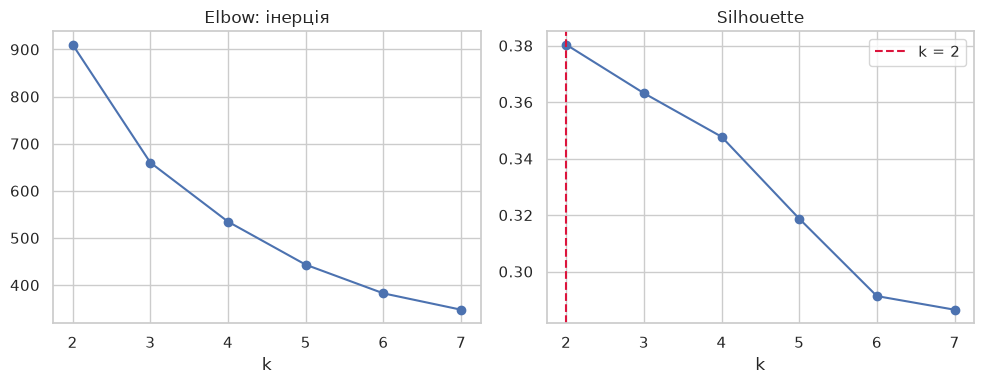

In [13]:
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

k_range = range(2, 8)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(df_ml)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(df_ml, labels))

best_k = int(list(k_range)[int(np.argmax(silhouettes))])
print("Silhouette:", {k: round(float(score), 3) for k, score in zip(k_range, silhouettes)})
print("Обране k:", best_k)
if best_k == 2:
    print("Дві групи зазвичай відділяють холодну половину року від теплої. Далі для сівозміни важливіший прогноз сезону.")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_xlabel("k")
axes[0].set_title("Elbow: інерція")
axes[1].plot(list(k_range), silhouettes, marker="o")
axes[1].axvline(best_k, color="crimson", ls="--", label=f"k = {best_k}")
axes[1].set_xlabel("k")
axes[1].set_title("Silhouette")
axes[1].legend()
plt.tight_layout()
plt.show()


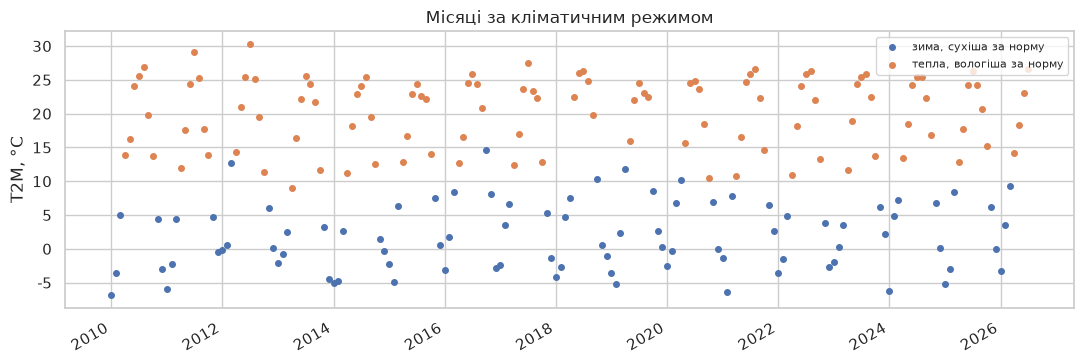

,,ALLSKY_SFC_SW_DWN,GWETROOT,GWETTOP,PRECTOTCORR,RH2M,T2M,T2M_MAX,T2M_MIN,n_months
cluster,regime,,,,,,,,,
0,"зима, сухіша за норму",10.13,0.60,0.61,1.13,73.97,1.76,19.24,-12.98,89
1,"тепла, вологіша за норму",19.76,0.57,0.57,3.24,67.40,20.28,34.30,6.89,110


In [14]:
SEASON_OF_MONTH = {
    12: "зима", 1: "зима", 2: "зима",
    3: "весна", 4: "весна", 5: "весна",
    6: "літо", 7: "літо", 8: "літо",
    9: "осінь", 10: "осінь", 11: "осінь",
}

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
monthly = df[feature_names].copy()
monthly["cluster"] = kmeans.fit_predict(df_ml)

regime_names = {}
for cluster, group in monthly.groupby("cluster"):
    seasons = group.index.month.map(SEASON_OF_MONTH)
    top = seasons.value_counts()
    season = top.index[0]
    share = top.iloc[0] / len(group)
    if group["PRECTOTCORR"].mean() >= monthly["PRECTOTCORR"].median():
        moisture = "вологіша за норму"
    else:
        moisture = "сухіша за норму"
    if share >= 0.55:
        regime_names[cluster] = f"{season}, {moisture}"
    else:
        warmth = "тепла" if group["T2M"].mean() >= monthly["T2M"].median() else "холодна"
        regime_names[cluster] = f"{warmth}, {moisture}"

name_counts = pd.Series(list(regime_names.values())).value_counts()
for cluster, name in list(regime_names.items()):
    if name_counts[name] > 1:
        t_mean = monthly.loc[monthly["cluster"] == cluster, "T2M"].mean()
        regime_names[cluster] = f"{name}, ~{t_mean:.0f}°C"

monthly["regime"] = monthly["cluster"].map(regime_names)

profile = monthly.groupby(["cluster", "regime"])[feature_names].mean().round(2)
profile["n_months"] = monthly.groupby(["cluster", "regime"]).size()
profile = profile.sort_values("T2M")

fig, ax = plt.subplots(figsize=(11, 3.8))
for cluster, name in sorted(regime_names.items()):
    part = monthly[monthly["cluster"] == cluster]
    ax.scatter(part.index, part["T2M"], s=16, label=name)
ax.set_ylabel("T2M, °C")
ax.set_title("Місяці за кліматичним режимом")
ax.legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

profile


## Крок 6. Прогноз наступного сезону

Модель — `RandomForestRegressor`. Для кожного горизонту від 1 до 18 місяців вона бачить лише те, що відомо в місяці-відліку:

- погоду цього місяця і двох попередніх;
- той самий календарний місяць рік або два тому;
- номер місяця, на який робимо прогноз (sin/cos), бо календар відомий наперед.

Ціль — виміри NASA POWER: середня і максимальна температура, опади й вологість кореневої зони. Останні 24 місяці відкладені. Поруч рахуємо сезонний бейзлайн: буде як у цьому місяці рік тому. MAE рахується так: модель стоїть в одному з минулих місяців і дивиться на `h` місяців уперед, знаючи погоду лише до місяця-відліку.

У сценарій для фермера по кожному показнику йде метод із меншим MAE на горизонтах 1, 3 і 6 місяців. Після перевірки ліс донавчається на всьому ряді й будує прямий прогноз на 18 місяців: власні прогнози назад у ознаки не підставляються.


Кліматичний ряд: 2010-01 — 2026-07, 199 місяців. Зразків для прогнозу: 3291.
Перевірка на місяцях від 2024-08. Менший MAE кращий.
T2M: ліс 1.903 °C, сезонний бейзлайн 1.497 °C → seasonal_naive
T2M_MAX: ліс 2.386 °C, сезонний бейзлайн 2.995 °C → random_forest
PRECTOTCORR: ліс 0.899 мм/день, сезонний бейзлайн 0.994 мм/день → random_forest
GWETROOT: ліс 0.025 частка, сезонний бейзлайн 0.032 частка → random_forest


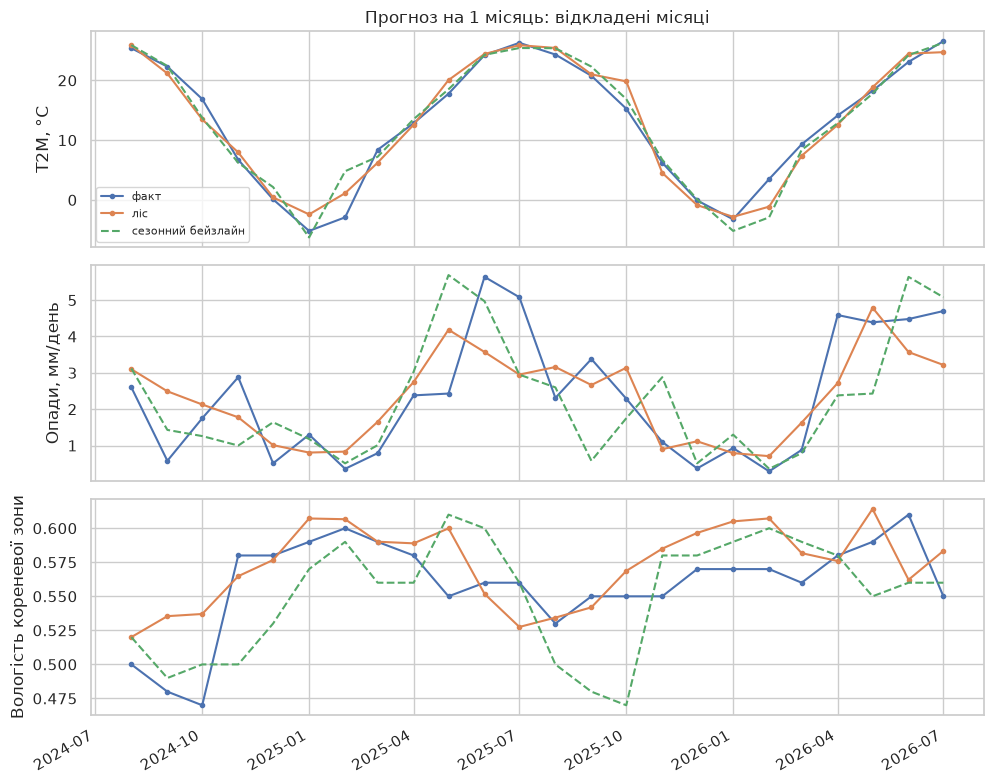

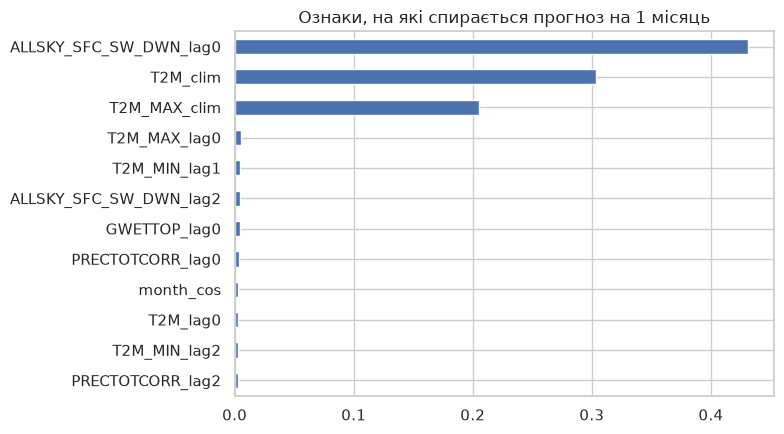

,горизонт,показник,одиниця,модель,MAE,R2
0,1,GWETROOT,частка,random_forest,0.024,0.230
1,1,GWETROOT,частка,seasonal_naive,0.032,-0.309
2,1,PRECTOTCORR,мм/день,random_forest,0.912,0.572
3,1,PRECTOTCORR,мм/день,seasonal_naive,0.994,0.346
4,1,T2M,°C,random_forest,1.640,0.957
5,1,T2M,°C,seasonal_naive,1.497,0.946
6,1,T2M_MAX,°C,random_forest,2.275,0.892
7,1,T2M_MAX,°C,seasonal_naive,2.995,0.856
8,3,GWETROOT,частка,random_forest,0.024,0.222
9,3,GWETROOT,частка,seasonal_naive,0.032,-0.309


In [15]:
TARGET_COLS = ["T2M", "T2M_MAX", "PRECTOTCORR", "GWETROOT"]
HORIZON_MAX = 18
HOLDOUT_MONTHS = 24
CHOICE_HORIZONS = (1, 3, 6)
UNITS = {
    "T2M": "°C",
    "T2M_MAX": "°C",
    "PRECTOTCORR": "мм/день",
    "GWETROOT": "частка",
}
RF_PARAMS = dict(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=1,
)

climate = df[feature_names].copy()
climate.index = pd.DatetimeIndex(pd.to_datetime(climate.index)).normalize()
row_by_month = {pd.Timestamp(ts): climate.iloc[i] for i, ts in enumerate(climate.index)}


def add_months(ts, months):
    base = pd.Timestamp(ts.year, ts.month, 1)
    shifted = base + pd.DateOffset(months=int(months))
    return pd.Timestamp(shifted.year, shifted.month, 1)


def features_at(origin, horizon):
    origin = add_months(origin, 0)
    row = {}
    for lag in (0, 1, 2):
        ts = add_months(origin, -lag)
        if ts not in row_by_month:
            return None
        values = row_by_month[ts]
        for col in feature_names:
            row[f"{col}_lag{lag}"] = float(values[col])
    target = add_months(origin, horizon)
    anchor = None
    for back in (12, 24, 36):
        cand = add_months(target, -back)
        if cand <= origin and cand in row_by_month:
            anchor = cand
            break
    if anchor is None:
        return None
    anchor_values = row_by_month[anchor]
    for col in TARGET_COLS:
        row[f"{col}_clim"] = float(anchor_values[col])
    row["month_sin"] = float(np.sin(2 * np.pi * target.month / 12.0))
    row["month_cos"] = float(np.cos(2 * np.pi * target.month / 12.0))
    return row


probe = None
for origin_probe in climate.index:
    probe = features_at(origin_probe, 1)
    if probe is not None:
        break
if probe is None:
    raise RuntimeError("Не вистачає історії, щоб зібрати ознаки прогнозу.")

FEATURE_COLS = list(probe.keys())
Y_COLS = [f"y_{col}" for col in TARGET_COLS]

records = []
for origin_month in climate.index:
    for horizon in range(1, HORIZON_MAX + 1):
        target = add_months(origin_month, horizon)
        if target not in row_by_month:
            continue
        features = features_at(origin_month, horizon)
        if features is None:
            continue
        record = {"horizon": horizon, "target": target, "origin": add_months(origin_month, 0)}
        record.update(features)
        target_values = row_by_month[target]
        for col in TARGET_COLS:
            record[f"y_{col}"] = float(target_values[col])
        records.append(record)

samples = pd.DataFrame.from_records(records)
print(
    f"Кліматичний ряд: {climate.index.min():%Y-%m} — {climate.index.max():%Y-%m}, "
    f"{len(climate)} місяців. Зразків для прогнозу: {len(samples)}."
)

test_start = add_months(climate.index.max(), -(HOLDOUT_MONTHS - 1))


def safe_r2(y_true, y_pred):
    if float(np.nanstd(y_true)) < 1e-8:
        return float("nan")
    return float(r2_score(y_true, y_pred))


def predict_frame(model, frame):
    predicted = model.predict(frame[FEATURE_COLS])
    out = pd.DataFrame(predicted, index=frame.index, columns=TARGET_COLS)
    out["PRECTOTCORR"] = out["PRECTOTCORR"].clip(lower=0)
    out["GWETROOT"] = out["GWETROOT"].clip(0, 1)
    return out


models_holdout = {}
metric_rows = []
holdout_frames = {}

for horizon in range(1, HORIZON_MAX + 1):
    part = samples.loc[samples["horizon"] == horizon].copy()
    train_mask = part["target"] < test_start
    test_mask = part["target"] >= test_start
    if int(train_mask.sum()) < 30 or int(test_mask.sum()) < 6:
        raise RuntimeError(f"Замало рядків для горизонту {horizon}.")
    model = RandomForestRegressor(**RF_PARAMS)
    model.fit(part.loc[train_mask, FEATURE_COLS], part.loc[train_mask, Y_COLS])
    models_holdout[horizon] = model

    test = part.loc[test_mask].copy()
    predicted = predict_frame(model, test)
    predicted.index = pd.DatetimeIndex(pd.to_datetime(test["target"]))
    actual = test[Y_COLS].copy()
    actual.columns = TARGET_COLS
    actual.index = predicted.index
    naive = test[[f"{col}_clim" for col in TARGET_COLS]].copy()
    naive.columns = TARGET_COLS
    naive.index = predicted.index
    holdout_frames[horizon] = (actual, predicted, naive)

    for col in TARGET_COLS:
        metric_rows.append({
            "horizon": horizon,
            "target": col,
            "unit": UNITS[col],
            "model": "random_forest",
            "MAE": mean_absolute_error(actual[col], predicted[col]),
            "R2": safe_r2(actual[col], predicted[col]),
        })
        metric_rows.append({
            "horizon": horizon,
            "target": col,
            "unit": UNITS[col],
            "model": "seasonal_naive",
            "MAE": mean_absolute_error(actual[col], naive[col]),
            "R2": safe_r2(actual[col], naive[col]),
        })

metrics_table = pd.DataFrame(metric_rows)
method_choice = {}
print(f"Перевірка на місяцях від {test_start:%Y-%m}. Менший MAE кращий.")
for col in TARGET_COLS:
    subset = metrics_table[
        metrics_table["target"].eq(col) & metrics_table["horizon"].isin(CHOICE_HORIZONS)
    ]
    mae_rf = float(subset.loc[subset["model"].eq("random_forest"), "MAE"].mean())
    mae_naive = float(subset.loc[subset["model"].eq("seasonal_naive"), "MAE"].mean())
    method_choice[col] = "random_forest" if mae_rf < mae_naive else "seasonal_naive"
    print(
        f"{col}: ліс {mae_rf:.3f} {UNITS[col]}, "
        f"сезонний бейзлайн {mae_naive:.3f} {UNITS[col]} → {method_choice[col]}"
    )

actual_h1, pred_h1, naive_h1 = holdout_frames[1]
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, col, title in zip(
    axes,
    ["T2M", "PRECTOTCORR", "GWETROOT"],
    ["T2M, °C", "Опади, мм/день", "Вологість кореневої зони"],
):
    ax.plot(actual_h1.index, actual_h1[col], marker="o", ms=3, label="факт")
    ax.plot(pred_h1.index, pred_h1[col], marker="o", ms=3, label="ліс")
    ax.plot(naive_h1.index, naive_h1[col], ls="--", label="сезонний бейзлайн")
    ax.set_ylabel(title)
axes[0].legend(loc="best", fontsize=8)
axes[0].set_title("Прогноз на 1 місяць: відкладені місяці")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

raw_importance = models_holdout[1].feature_importances_
if isinstance(raw_importance, list):
    raw_importance = np.mean(np.asarray(raw_importance), axis=0)
importances = pd.Series(raw_importance, index=FEATURE_COLS)
importances = importances.sort_values(ascending=False).head(12).sort_values()
plt.figure(figsize=(8, 4.5))
importances.plot.barh()
plt.title("Ознаки, на які спирається прогноз на 1 місяць")
plt.tight_layout()
plt.show()

shown = metrics_table[metrics_table["horizon"].isin((1, 3, 6, 12))].copy()
shown["MAE"] = shown["MAE"].round(3)
shown["R2"] = shown["R2"].round(3)
shown = shown.sort_values(["horizon", "target", "model"]).reset_index(drop=True)
shown = shown.rename(columns={
    "horizon": "горизонт",
    "target": "показник",
    "unit": "одиниця",
    "model": "модель",
})
shown


У сценарій сезону для кожного показника йде метод із меншим MAE на горизонтах 1, 3 і 6 місяців.
  T2M: seasonal_naive
  T2M_MAX: random_forest
  PRECTOTCORR: random_forest
  GWETROOT: random_forest


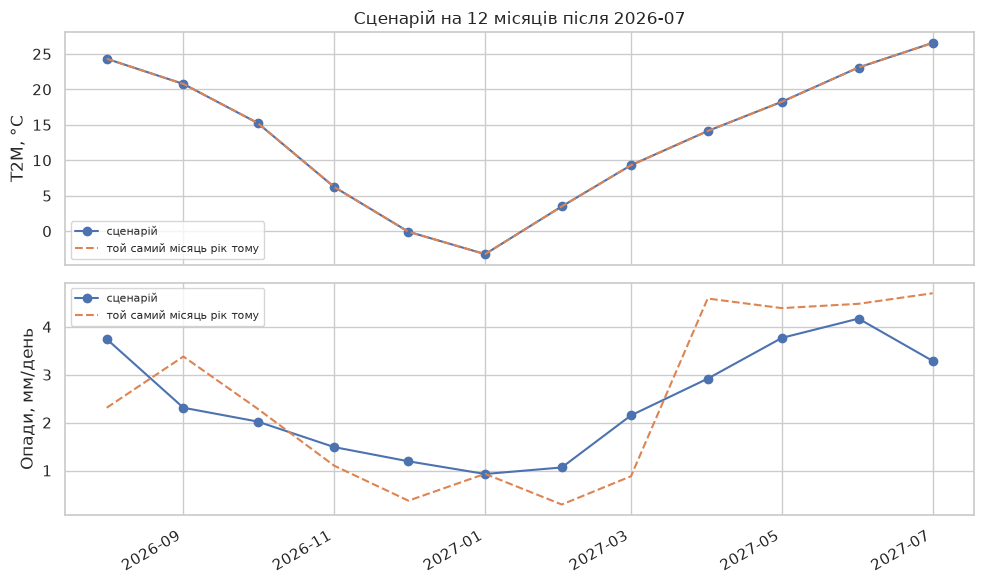

,T2M,T2M_MAX,PRECTOTCORR,GWETROOT
2026-08-01,24.31,37.58,3.74,0.54
2026-09-01,20.76,35.95,2.31,0.53
2026-10-01,15.26,31.24,2.02,0.54
2026-11-01,6.23,23.22,1.49,0.56
2026-12-01,-0.08,15.02,1.19,0.59
2027-01-01,-3.24,14.66,0.93,0.59
2027-02-01,3.49,21.43,1.06,0.58
2027-03-01,9.30,28.69,2.15,0.58
2027-04-01,14.12,29.18,2.92,0.58
2027-05-01,18.25,32.46,3.77,0.59


In [16]:
models_full = {}
for horizon in range(1, HORIZON_MAX + 1):
    part = samples.loc[samples["horizon"] == horizon]
    model = RandomForestRegressor(**RF_PARAMS)
    model.fit(part[FEATURE_COLS], part[Y_COLS])
    models_full[horizon] = model

origin = climate.index.max()
future_index = [add_months(origin, horizon) for horizon in range(1, HORIZON_MAX + 1)]
scenario = pd.DataFrame(index=pd.DatetimeIndex(future_index), columns=TARGET_COLS, dtype=float)

for horizon, ts in enumerate(future_index, start=1):
    features = features_at(origin, horizon)
    if features is None:
        raise RuntimeError(f"Немає ознак для горизонту {horizon}.")
    frame = pd.DataFrame([features])
    forest_hat = predict_frame(models_full[horizon], frame).iloc[0]
    for col in TARGET_COLS:
        if method_choice[col] == "random_forest":
            scenario.at[ts, col] = float(forest_hat[col])
        else:
            scenario.at[ts, col] = float(features[f"{col}_clim"])

scenario["PRECTOTCORR"] = scenario["PRECTOTCORR"].clip(lower=0)
scenario["GWETROOT"] = scenario["GWETROOT"].clip(0, 1)

print("У сценарій сезону для кожного показника йде метод із меншим MAE на горизонтах 1, 3 і 6 місяців.")
for col, method in method_choice.items():
    print(f"  {col}: {method}")

coming = scenario.iloc[:12]
year_ago = [add_months(ts, -12) for ts in coming.index]
if any(ts not in row_by_month for ts in year_ago):
    raise RuntimeError("Бракує минулого року для порівняння зі сценарієм.")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(coming.index, coming["T2M"], marker="o", label="сценарій")
axes[0].plot(
    coming.index,
    [float(row_by_month[ts]["T2M"]) for ts in year_ago],
    ls="--",
    label="той самий місяць рік тому",
)
axes[0].set_ylabel("T2M, °C")
axes[0].legend(fontsize=8)
axes[0].set_title(f"Сценарій на 12 місяців після {origin:%Y-%m}")
axes[1].plot(coming.index, coming["PRECTOTCORR"], marker="o", label="сценарій")
axes[1].plot(
    coming.index,
    [float(row_by_month[ts]["PRECTOTCORR"]) for ts in year_ago],
    ls="--",
    label="той самий місяць рік тому",
)
axes[1].set_ylabel("Опади, мм/день")
axes[1].legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

coming.round(2)


## Крок 7. Три сівозміни

Челендж [Field Shift: Adapting Farms with NASA Data](https://www.spaceappschallenge.org/2026/challenges/adapting-farms-with-nasa-data/) просить порівняти щонайменше три сівозміни, включно з поточною. У бал входять дані NASA POWER, локальний опис ґрунту, властивості культур і пріоритети фермера.

- Теплий сезон для кукурудзи, сої, сорго, соняшнику і люцерни — квітень–вересень.
- Озима пшениця оцінюється за опадами жовтня–червня і температурою березня–червня: у липні її вже зібрано.
- Поріг води — частка від типових опадів цієї точки, тож шкала прив'язана до завантаженого ряду.
- `LOCAL_SOIL` і `FARMER_PRIORITIES` можна змінити. pH нижче 6.2 знижує бал люцерни.
- Три роки кожної сівозміни перевіряються на кліматі одного наступного сезону. Це стрес-тест «якщо такий сезон повториться». Окремо стоїть середній бал останніх повних сезонів.

Підсумок = 0.6 × бал сценарію + 0.4 × історичний бал. Усередині балу сезону ваги такі: вода 0.40, кліматична придатність 0.30, ґрунт 0.30. Ціни зерна в розрахунок не входять.


Локальний ґрунт: silt loam, pH 6.5 — Орієнтир для 40°N, 96°W. Замініть на аналіз свого поля.
Типові опади цієї точки: теплий сезон 606 мм, вікно пшениці 538 мм.
GWETROOT теплого сезону: сухий хвіст 0.500, медіана 0.560.
               t_min  t_max  t_hot  drought  water_mm
crop                                                 
кукурудза         18     30     36     0.25     654.0
соя               18     30     36     0.50     594.0
озима пшениця      8     22     33     0.70     485.0
сорго             20     34     40     0.90     454.0
люцерна           14     28     37     0.55     636.0
соняшник          16     32     38     0.80     497.0


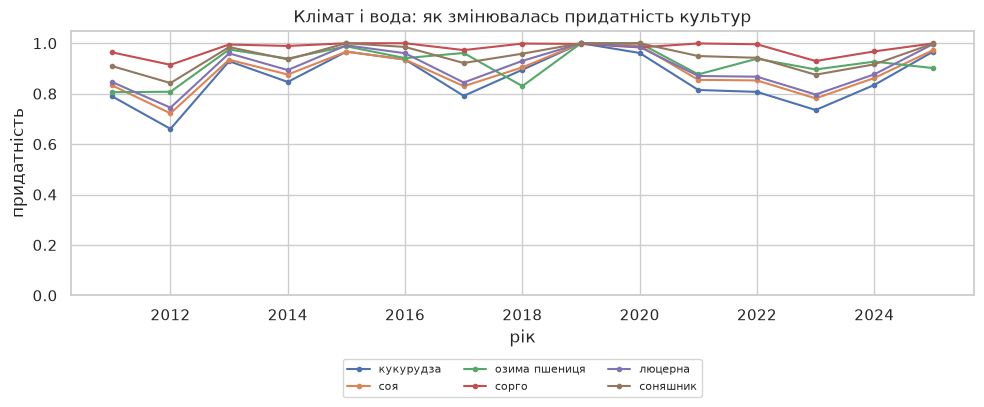

Сезон, під який підганяємо сівозміну: 2027.


,t_mean,t_max,precip_mm,water_mm,gwetroot,temperature,water,heat
crop,,,,,,,,
кукурудза,21.2,39.5,607.0,654.0,0.56,1.0,0.95,0.56
соя,21.2,39.5,607.0,594.0,0.56,1.0,1.00,0.56
озима пшениця,16.2,36.3,599.0,485.0,0.59,1.0,1.00,0.58
сорго,21.2,39.5,607.0,454.0,0.56,1.0,1.00,1.00
люцерна,21.2,39.5,607.0,636.0,0.56,1.0,0.98,0.69
соняшник,21.2,39.5,607.0,497.0,0.56,1.0,1.00,0.81


In [17]:
# Локальний опис поля. Це вводить фермер, POWER такого шару не віддає.
LOCAL_SOIL = {
    "texture": "silt loam",
    "ph": 6.5,
    "drainage": "moderate",
    "note": "Орієнтир для 40°N, 96°W. Замініть на аналіз свого поля.",
}

# Ваги рішення. Сума може бути будь-якою: далі ділимо на неї.
FARMER_PRIORITIES = {
    "soil_health": 0.30,
    "water": 0.40,
    "climate_fit": 0.30,
}

CROPS = pd.DataFrame([
    {"crop": "кукурудза", "t_min": 18, "t_max": 30, "t_hot": 36, "drought": 0.25, "water_factor": 1.08, "n_fix": 0.0, "soil_cover": 0.40, "deep_root": 0.30},
    {"crop": "соя", "t_min": 18, "t_max": 30, "t_hot": 36, "drought": 0.50, "water_factor": 0.98, "n_fix": 1.0, "soil_cover": 0.50, "deep_root": 0.40},
    {"crop": "озима пшениця", "t_min": 8, "t_max": 22, "t_hot": 33, "drought": 0.70, "water_factor": 0.90, "n_fix": 0.0, "soil_cover": 0.85, "deep_root": 0.55},
    {"crop": "сорго", "t_min": 20, "t_max": 34, "t_hot": 40, "drought": 0.90, "water_factor": 0.75, "n_fix": 0.0, "soil_cover": 0.45, "deep_root": 0.70},
    {"crop": "люцерна", "t_min": 14, "t_max": 28, "t_hot": 37, "drought": 0.55, "water_factor": 1.05, "n_fix": 0.95, "soil_cover": 0.95, "deep_root": 1.00},
    {"crop": "соняшник", "t_min": 16, "t_max": 32, "t_hot": 38, "drought": 0.80, "water_factor": 0.82, "n_fix": 0.0, "soil_cover": 0.40, "deep_root": 0.85},
]).set_index("crop")


def ph_factor(crop_name):
    ph = float(LOCAL_SOIL["ph"])
    if crop_name == "люцерна" and ph < 6.2:
        return 0.75
    if ph < 5.5 or ph > 8.0:
        return 0.80
    return 1.0


def window_metrics(series, year, crop_name):
    if crop_name == "озима пшениця":
        months = pd.date_range(pd.Timestamp(year - 1, 10, 1), periods=9, freq="MS")
        growth_months = (3, 4, 5, 6)
        heat_months = (4, 5, 6)
    else:
        months = pd.date_range(pd.Timestamp(year, 4, 1), periods=6, freq="MS")
        growth_months = (4, 5, 6, 7, 8, 9)
        heat_months = (4, 5, 6, 7, 8, 9)
    months = pd.DatetimeIndex(months)
    if not months.isin(series.index).all():
        return None
    part = series.loc[months]
    growth = part[part.index.month.isin(growth_months)]
    heat = part[part.index.month.isin(heat_months)]
    if growth.empty or heat.empty:
        return None
    days = pd.Series(part.index, index=part.index).dt.days_in_month
    return {
        "t_mean": float(growth["T2M"].mean()),
        "t_max": float(heat["T2M_MAX"].max()),
        "precip_mm": float((part["PRECTOTCORR"] * days).sum()),
        "gwetroot": float(growth["GWETROOT"].mean()),
    }


def band_score(value, low, high, width):
    if low <= value <= high:
        return 1.0
    distance = (low - value) if value < low else (value - high)
    return float(max(0.0, 1.0 - distance / width))


warm_rows = climate[climate.index.month.isin((4, 5, 6, 7, 8, 9))]
GWET_DRY = float(warm_rows["GWETROOT"].quantile(0.10))
GWET_REF = float(warm_rows["GWETROOT"].median())
if GWET_REF <= GWET_DRY:
    GWET_REF = GWET_DRY + 0.01


def suitability_parts(metrics, crop_name):
    crop = CROPS.loc[crop_name]
    temperature = band_score(metrics["t_mean"], crop["t_min"], crop["t_max"], 8)
    if metrics["t_max"] <= crop["t_hot"]:
        heat = 1.0
    else:
        heat = max(0.0, 1.0 - (metrics["t_max"] - crop["t_hot"]) / 8.0)
    ratio = metrics["precip_mm"] / float(crop["water_mm"])
    shortfall = max(0.0, 1.0 - ratio)
    rain = 1.0 - shortfall * (1.0 - 0.75 * float(crop["drought"]))
    rain = float(np.clip(rain, 0, 1))
    if metrics["gwetroot"] >= GWET_REF:
        moist = 1.0
    else:
        moist = (metrics["gwetroot"] - GWET_DRY) / (GWET_REF - GWET_DRY)
    moist = float(np.clip(moist, 0, 1))
    moist = 1.0 - (1.0 - moist) * (1.0 - float(crop["drought"]))
    water = float(np.clip(0.8 * rain + 0.2 * moist, 0, 1))
    factor = ph_factor(crop_name)
    return {
        "temperature": float(temperature * factor),
        "water": float(water * factor),
        "heat": float(heat * factor),
    }


def season_year_from(last_month):
    if int(last_month.month) < 4:
        return int(last_month.year)
    return int(last_month.year) + 1


combined = pd.concat([climate[TARGET_COLS], scenario[TARGET_COLS]])
combined = combined[~combined.index.duplicated(keep="last")].sort_index()

observed_years = []
for year in range(int(climate.index.year.min()), int(climate.index.year.max()) + 1):
    warm = window_metrics(climate, year, "кукурудза")
    wheat = window_metrics(climate, year, "озима пшениця")
    if warm is None or wheat is None:
        continue
    observed_years.append({
        "year": year,
        "warm_mm": warm["precip_mm"],
        "warm_t": warm["t_mean"],
        "warm_tmax": warm["t_max"],
        "wheat_mm": wheat["precip_mm"],
    })

year_table = pd.DataFrame(observed_years)
median_warm = float(year_table["warm_mm"].median())
median_wheat = float(year_table["wheat_mm"].median())
CROPS["water_mm"] = [
    float(CROPS.loc[crop, "water_factor"]) * (median_wheat if crop == "озима пшениця" else median_warm)
    for crop in CROPS.index
]

print("Локальний ґрунт:", LOCAL_SOIL["texture"] + ",", "pH", LOCAL_SOIL["ph"] , "—", LOCAL_SOIL["note"])
print(f"Типові опади цієї точки: теплий сезон {median_warm:.0f} мм, вікно пшениці {median_wheat:.0f} мм.")
print(f"GWETROOT теплого сезону: сухий хвіст {GWET_DRY:.3f}, медіана {GWET_REF:.3f}.")
crop_card = CROPS[["t_min", "t_max", "t_hot", "drought", "water_mm"]].copy()
crop_card["water_mm"] = crop_card["water_mm"].round(0)
print(crop_card)

score_rows = []
for year in year_table["year"]:
    for crop in CROPS.index:
        metrics = window_metrics(climate, int(year), crop)
        parts = suitability_parts(metrics, crop)
        thermal = 0.6 * parts["temperature"] + 0.4 * parts["heat"]
        score_rows.append({
            "year": int(year),
            "crop": crop,
            "fit": 0.5 * thermal + 0.5 * parts["water"],
        })
crop_history = pd.DataFrame(score_rows)

fig, ax = plt.subplots(figsize=(10, 4.4))
for crop in CROPS.index:
    part = crop_history[crop_history["crop"] == crop]
    ax.plot(part["year"], part["fit"], marker="o", ms=3, label=crop)
ax.set_ylabel("придатність")
ax.set_xlabel("рік")
ax.set_ylim(0, 1.05)
ax.set_title("Клімат і вода: як змінювалась придатність культур")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

plan_year = season_year_from(origin)
plan_rows = []
for crop in CROPS.index:
    metrics = window_metrics(combined, plan_year, crop)
    if metrics is None:
        raise RuntimeError(f"У сценарії немає повного вікна для культури «{crop}», сезон {plan_year}.")
    parts = suitability_parts(metrics, crop)
    plan_rows.append({
        "crop": crop,
        "t_mean": round(metrics["t_mean"], 1),
        "t_max": round(metrics["t_max"], 1),
        "precip_mm": round(metrics["precip_mm"], 0),
        "water_mm": round(float(CROPS.loc[crop, "water_mm"]), 0),
        "gwetroot": round(metrics["gwetroot"], 2),
        "temperature": round(parts["temperature"], 2),
        "water": round(parts["water"], 2),
        "heat": round(parts["heat"], 2),
    })
plan_crops = pd.DataFrame(plan_rows).set_index("crop")
print(f"Сезон, під який підганяємо сівозміну: {plan_year}.")
plan_crops


Тренд теплих сезонів 2011–2025: температура +0.017 °C/рік, опади +0.7 мм/рік.
Сценарій 2027: 607 мм за квітень–вересень (типово 606 мм), середня T 21.2 °C, найспекотніший місяць 39.5 °C.
Пріоритети: {'soil_health': 0.3, 'water': 0.4, 'climate_fit': 0.3}
Підсумковий бал = 0.6 × бал наступного сезону + 0.4 × середнє за 2021–2025.


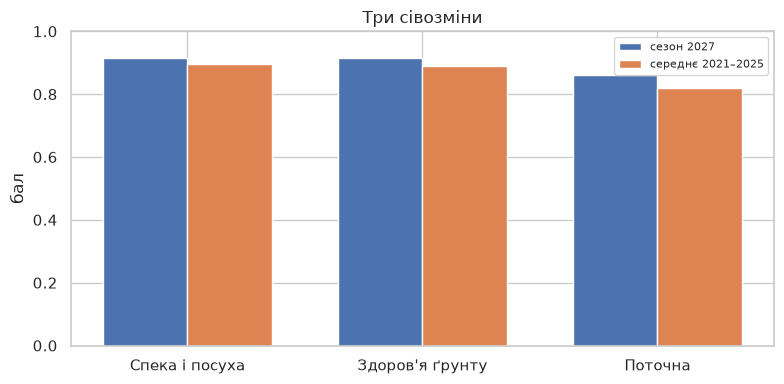

Рекомендація: Спека і посуха — сорго → соя → озима пшениця.
Сорго витримує спекотний місяць і менші опади, соя повертає азот, пшениця закриває ґрунт узимку.
Її бал 0.908. Поточна сівозміна: 0.845.
Відрив від «Здоров'я ґрунту» — 0.003. Обидві сівозміни попереду поточної і майже рівні між собою: зміна ваг пріоритетів може поміняти лідера.
Спека і посуха (сорго → соя → озима пшениця): соя: спекотний місяць, Tmax 39.5 °C; озима пшениця: спекотний місяць, Tmax 36.3 °C
Здоров'я ґрунту (соя → озима пшениця → люцерна): соя: спекотний місяць, Tmax 39.5 °C; озима пшениця: спекотний місяць, Tmax 36.3 °C; люцерна: спекотний місяць, Tmax 39.5 °C
Поточна (кукурудза → соя → кукурудза): кукурудза: спекотний місяць, Tmax 39.5 °C; соя: спекотний місяць, Tmax 39.5 °C


,name,sequence,climate_fit,water,soil,plan_score,history_score,rank_score
0,Спека і посуха,сорго → соя → озима пшениця,0.886,1.000,0.830,0.915,0.897,0.908
1,Здоров'я ґрунту,соя → озима пшениця → люцерна,0.844,0.993,0.883,0.915,0.891,0.905
2,Поточна,кукурудза → соя → кукурудза,0.824,0.969,0.753,0.861,0.821,0.845


In [18]:
def priority_score(climate_fit, water, soil):
    weights = FARMER_PRIORITIES
    total = float(sum(weights.values()))
    return (
        weights["climate_fit"] * climate_fit
        + weights["water"] * water
        + weights["soil_health"] * soil
    ) / total


def soil_sequence_score(crops):
    rows = CROPS.loc[list(crops)]
    gaps = max(len(crops) - 1, 1)
    repeats = sum(left == right for left, right in zip(crops, crops[1:]))
    diversity = 1.0 - repeats / gaps
    nfix = rows["n_fix"].to_numpy(dtype=float)
    has_fixer = 1.0 if float(nfix.max()) >= 0.8 else 0.0
    handover = 0.0
    for left, right in zip(crops, crops[1:]):
        if float(CROPS.loc[left, "n_fix"]) < 0.5 and float(CROPS.loc[right, "n_fix"]) >= 0.8:
            handover = 1.0
    if handover == 0.0 and float(nfix[0]) >= 0.8:
        handover = 0.5
    nitrogen = 0.6 * has_fixer + 0.4 * handover
    cover = float(rows["soil_cover"].mean())
    roots = float(rows["deep_root"].mean())
    return float(0.30 * diversity + 0.30 * nitrogen + 0.20 * cover + 0.20 * roots)


def rotation_components(crops, year, series):
    metrics = {}
    parts = {}
    for crop in crops:
        crop_metrics = window_metrics(series, year, crop)
        if crop_metrics is None:
            return None
        metrics[crop] = crop_metrics
        parts[crop] = suitability_parts(crop_metrics, crop)
    climate_fit = float(np.mean([
        0.6 * parts[crop]["temperature"] + 0.4 * parts[crop]["heat"] for crop in crops
    ]))
    water = float(np.mean([parts[crop]["water"] for crop in crops]))
    soil = soil_sequence_score(crops)
    return {
        "climate_fit": climate_fit,
        "water": water,
        "soil": soil,
        "score": float(priority_score(climate_fit, water, soil)),
        "metrics": metrics,
        "parts": parts,
    }


def unique_keep(items):
    seen = []
    for item in items:
        if item not in seen:
            seen.append(item)
    return seen


def rotation_risks(crops, metrics, parts):
    risks = []
    for crop in crops:
        need = float(CROPS.loc[crop, "water_mm"])
        got = metrics[crop]["precip_mm"]
        if got < 0.9 * need and float(CROPS.loc[crop, "drought"]) < 0.75:
            risks.append(f"{crop}: води менше за орієнтир ({got:.0f} мм проти {need:.0f} мм)")
        if parts[crop]["heat"] < 0.75:
            risks.append(f"{crop}: спекотний місяць, Tmax {metrics[crop]['t_max']:.1f} °C")
    if any(left == right for left, right in zip(crops, crops[1:])):
        risks.append("та сама культура два роки поспіль послаблює структуру ґрунту")
    if float(CROPS.loc[list(crops), "n_fix"].max()) < 0.8:
        risks.append("немає бобової, азот ґрунту не відновлюється")
    risks = unique_keep(risks)
    if not risks:
        risks.append("явних ризиків за цим сценарієм немає")
    return risks


ROTATIONS = [
    {
        "name": "Поточна",
        "crops": ["кукурудза", "соя", "кукурудза"],
        "why": "База порівняння для цієї точки: кукурудза і соя, на третій рік знову кукурудза.",
    },
    {
        "name": "Спека і посуха",
        "crops": ["сорго", "соя", "озима пшениця"],
        "why": "Сорго витримує спекотний місяць і менші опади, соя повертає азот, пшениця закриває ґрунт узимку.",
    },
    {
        "name": "Здоров'я ґрунту",
        "crops": ["соя", "озима пшениця", "люцерна"],
        "why": "Бобові й зимове покриття тримають ґрунт закритим і відновлюють азот.",
    },
]

recent_years = [int(year) for year in year_table["year"].tail(5)]
ranking_rows = []
risks_by_name = {}
why_by_name = {}
for rotation in ROTATIONS:
    plan = rotation_components(rotation["crops"], plan_year, combined)
    if plan is None:
        raise RuntimeError(f"Немає сценарію для сівозміни «{rotation['name']}».")
    past_scores = []
    for year in recent_years:
        past = rotation_components(rotation["crops"], year, climate)
        if past is not None:
            past_scores.append(past["score"])
    if not past_scores:
        raise RuntimeError("Немає повних минулих сезонів для порівняння.")
    history_score = float(np.mean(past_scores))
    risks_by_name[rotation["name"]] = rotation_risks(rotation["crops"], plan["metrics"], plan["parts"])
    why_by_name[rotation["name"]] = rotation["why"]
    ranking_rows.append({
        "name": rotation["name"],
        "sequence": " → ".join(rotation["crops"]),
        "climate_fit": plan["climate_fit"],
        "water": plan["water"],
        "soil": plan["soil"],
        "plan_score": plan["score"],
        "history_score": history_score,
        "rank_score": 0.6 * plan["score"] + 0.4 * history_score,
    })

ranking = (
    pd.DataFrame(ranking_rows)
    .sort_values(["rank_score", "soil", "water"], ascending=False)
    .reset_index(drop=True)
)
for column in ("climate_fit", "water", "soil", "plan_score", "history_score", "rank_score"):
    ranking[column] = ranking[column].round(3)

years_arr = year_table["year"].to_numpy(dtype=float)
slope_t = float(np.polyfit(years_arr, year_table["warm_t"].to_numpy(dtype=float), 1)[0])
slope_p = float(np.polyfit(years_arr, year_table["warm_mm"].to_numpy(dtype=float), 1)[0])
warm_plan = window_metrics(combined, plan_year, "кукурудза")

print(
    f"Тренд теплих сезонів {int(year_table['year'].min())}–{int(year_table['year'].max())}: "
    f"температура {slope_t:+.3f} °C/рік, опади {slope_p:+.1f} мм/рік."
)
print(
    f"Сценарій {plan_year}: {warm_plan['precip_mm']:.0f} мм за квітень–вересень "
    f"(типово {median_warm:.0f} мм), середня T {warm_plan['t_mean']:.1f} °C, "
    f"найспекотніший місяць {warm_plan['t_max']:.1f} °C."
)
print(
    "Пріоритети:",
    FARMER_PRIORITIES,
)
print(
    "Підсумковий бал = 0.6 × бал наступного сезону + 0.4 × середнє за "
    f"{recent_years[0]}–{recent_years[-1]}."
)

fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(ranking))
width = 0.36
ax.bar(positions - width / 2, ranking["plan_score"], width, label=f"сезон {plan_year}")
ax.bar(
    positions + width / 2,
    ranking["history_score"],
    width,
    label=f"середнє {recent_years[0]}–{recent_years[-1]}",
)
ax.set_xticks(positions)
ax.set_xticklabels(ranking["name"])
ax.set_ylim(0, 1)
ax.set_ylabel("бал")
ax.set_title("Три сівозміни")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

winner = ranking.iloc[0]
current = ranking.loc[ranking["name"].eq("Поточна")].iloc[0]
print(f"Рекомендація: {winner['name']} — {winner['sequence']}.")
print(why_by_name[winner["name"]])
print(f"Її бал {winner['rank_score']:.3f}. Поточна сівозміна: {current['rank_score']:.3f}.")
second = ranking.iloc[1]
gap = float(winner["rank_score"] - second["rank_score"])
if gap < 0.02:
    print(
        f"Відрив від «{second['name']}» — {gap:.3f}. "
        "Обидві сівозміни попереду поточної і майже рівні між собою: "
        "зміна ваг пріоритетів може поміняти лідера."
    )
for _, row in ranking.iterrows():
    print(f"{row['name']} ({row['sequence']}): {'; '.join(risks_by_name[row['name']])}")

ranking


## Як читати рекомендацію

Вищий бал означає краще поєднання температури, води й користі для ґрунту за заданими вагами. Поточна сівозміна лишається в таблиці як база, навіть якщо інша набирає більше.

Поруч із цифрою варто тримати такі межі результату:

- ряд належить одній комірці NASA POWER (координати в кроці 2);
- `GWETROOT` — модельна вологість ґрунту в POWER;
- пороги культур — агрономічні орієнтири для планування;
- таблиця MAE в кроці 6 показує, наскільки сценарій тримається проти сезонного повтору.
